# 02 - Clustering Analysis
This notebook applies K-Means clustering on county-level EV features
to discover patterns in EV adoption across Washington State counties.

In [1]:
# The required libraries to run the code

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load the scaled and original county data
county_scaled = pd.read_csv('outputs/results/county_scaled.csv')
county_features = pd.read_csv('outputs/results/county_features.csv')

print("Data Loaded!")
print(f"county_scaled shape:   {county_scaled.shape}")
print(f"county_features shape: {county_features.shape}")
print(f"\nColumns available:")
print(county_scaled.columns.tolist())

Data Loaded!
county_scaled shape:   (246, 11)
county_features shape: (246, 11)

Columns available:
['County', 'Total_EVs', 'BEV_Count', 'PHEV_Count', 'Avg_Electric_Range', 'Unique_Makes', 'Unique_Models', 'Most_Common_Make', 'Avg_Model_Year', 'BEV_Proportion', 'PHEV_Proportion']


## Step 1: Find Optimal K using Elbow Method

In [3]:
# Select numeric features for clustering

numeric_cols = [
    'Total_EVs', 'BEV_Count', 'PHEV_Count',
    'Avg_Electric_Range', 'Unique_Makes', 'Unique_Models',
    'Avg_Model_Year', 'BEV_Proportion', 'PHEV_Proportion'
]

X = county_scaled[numeric_cols].values

print(f"Feature matrix shape: {X.shape}")
print(f"Features used: {numeric_cols}")

Feature matrix shape: (246, 9)
Features used: ['Total_EVs', 'BEV_Count', 'PHEV_Count', 'Avg_Electric_Range', 'Unique_Makes', 'Unique_Models', 'Avg_Model_Year', 'BEV_Proportion', 'PHEV_Proportion']


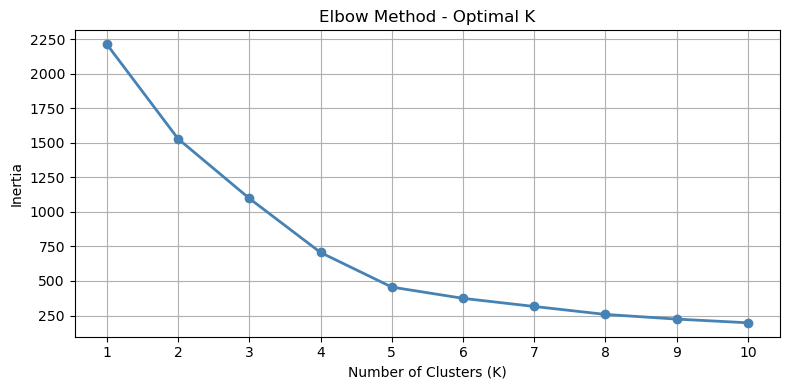

Elbow plot saved!


In [5]:
# Elbow Method - Inertia for K = 1 to 10

inertia = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    inertia.append(km.inertia_)

# Plot
plt.figure(figsize=(8, 4))
plt.plot(k_range, inertia, marker='o', color='steelblue', linewidth=2)
plt.title('Elbow Method - Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(k_range)
plt.grid(True)
plt.tight_layout()
plt.savefig('outputs/figures/elbow_plot.png', dpi=150)
plt.show()
print("Elbow plot saved!")

## Step 2: Confirm Optimal K using Silhouette Score

K=2  →  Silhouette Score: 0.8779
K=3  →  Silhouette Score: 0.4532
K=4  →  Silhouette Score: 0.4421
K=5  →  Silhouette Score: 0.5010
K=6  →  Silhouette Score: 0.4472
K=7  →  Silhouette Score: 0.4612
K=8  →  Silhouette Score: 0.4622
K=9  →  Silhouette Score: 0.4730
K=10  →  Silhouette Score: 0.4852


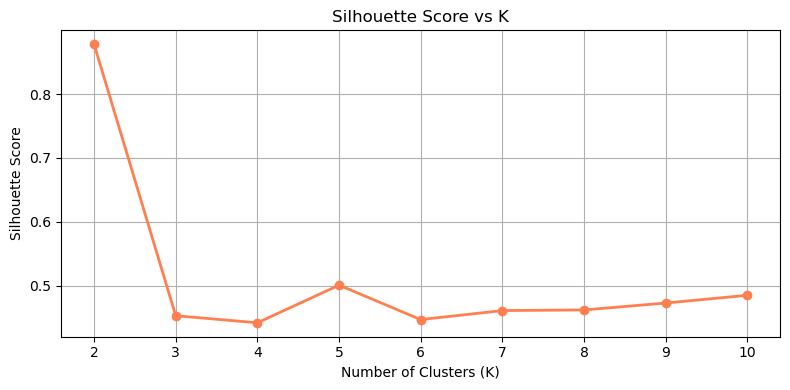

Silhouette plot saved!


In [6]:
# Silhouette Score for K = 2 to 10

sil_scores = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    score = silhouette_score(X, labels)
    sil_scores.append(score)
    print(f"K={k}  →  Silhouette Score: {score:.4f}")

# Plot
plt.figure(figsize=(8, 4))
plt.plot(k_range, sil_scores, marker='o', color='coral', linewidth=2)
plt.title('Silhouette Score vs K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(k_range)
plt.grid(True)
plt.tight_layout()
plt.savefig('outputs/figures/silhouette_plot.png', dpi=150)
plt.show()
print("Silhouette plot saved!")

## Step 3: Fit Final K-Means Model (K=4)

In [7]:
# Fit Final K-Means Model with K=4

K = 4

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
county_features['Cluster'] = kmeans.fit_predict(X)
county_scaled['Cluster'] = county_features['Cluster']

print(f"K-Means fitted with K={K}")
print(f"\nCluster Distribution:")
print(county_features['Cluster'].value_counts().sort_index())

print(f"\nSample counties per cluster:")
for c in range(K):
    counties = county_features[county_features['Cluster'] == c]['County'].tolist()
    print(f"\nCluster {c} ({len(counties)} counties): {counties[:5]} ...")

K-Means fitted with K=4

Cluster Distribution:
Cluster
0    156
1     59
2     30
3      1
Name: count, dtype: int64

Sample counties per cluster:

Cluster 0 (156 counties): ['Ada', 'Adams', 'Alameda', 'Albemarle', 'Alexandria'] ...

Cluster 1 (59 counties): ['Alachua', 'Allen', 'Anchorage', 'Arapahoe', 'Autauga'] ...

Cluster 2 (30 counties): ['Benton', 'Chelan', 'Clallam', 'Clark', 'Cowlitz'] ...

Cluster 3 (1 counties): ['King'] ...


## Step 4: Cluster Profile Analysis

In [8]:
# Cluster Profile - Mean of each feature per cluster

profile_cols = [
    'Total_EVs', 'BEV_Count', 'PHEV_Count',
    'Avg_Electric_Range', 'Unique_Makes', 'Unique_Models',
    'Avg_Model_Year', 'BEV_Proportion', 'PHEV_Proportion'
]

cluster_profile = county_features.groupby('Cluster')[profile_cols].mean().round(2)

print("Cluster Profiles (mean values per cluster):")
print(cluster_profile.to_string())

Cluster Profiles (mean values per cluster):
         Total_EVs  BEV_Count  PHEV_Count  Avg_Electric_Range  Unique_Makes  Unique_Models  Avg_Model_Year  BEV_Proportion  PHEV_Proportion
Cluster                                                                                                                                    
0             6.93       5.37        1.56               49.68          2.71           3.88         2021.84            0.92             0.08
1             2.20       0.73        1.47               34.36          2.02           2.08         2021.23            0.25             0.75
2          4535.90    3531.03     1004.87               44.71         32.43         107.97         2021.62            0.74             0.26
3        133815.00  109496.00    24319.00               38.69         44.00         179.00         2022.15            0.82             0.18


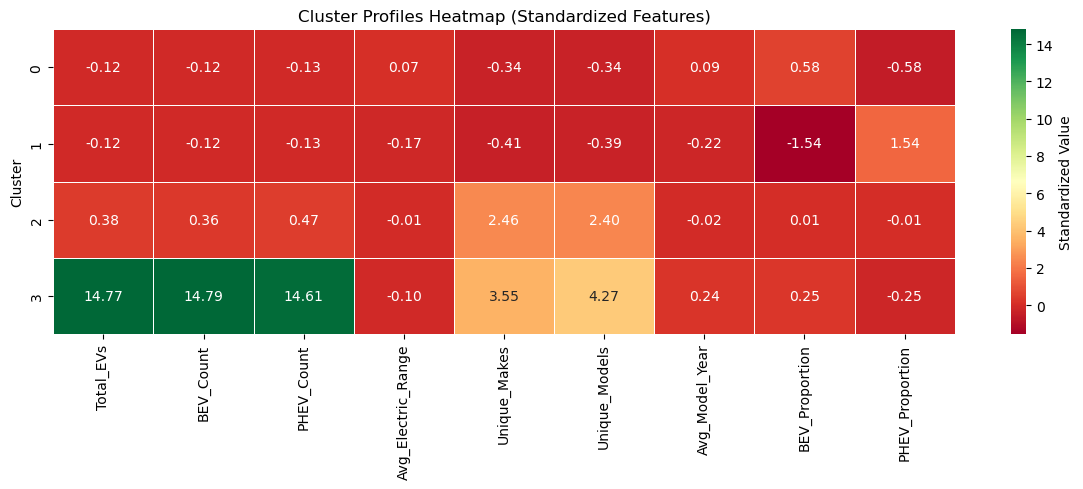

Heatmap saved!


In [9]:
# Heatmap of Cluster Profiles (using scaled data)

profile_scaled = county_scaled.groupby('Cluster')[profile_cols].mean()

plt.figure(figsize=(12, 5))
sns.heatmap(
    profile_scaled,
    annot=True, fmt='.2f',
    cmap='RdYlGn',
    linewidths=0.5,
    cbar_kws={'label': 'Standardized Value'}
)
plt.title('Cluster Profiles Heatmap (Standardized Features)')
plt.ylabel('Cluster')
plt.tight_layout()
plt.savefig('outputs/figures/cluster_heatmap.png', dpi=150)
plt.show()
print("Heatmap saved!")

## Step 5: Visualize Clusters using PCA

In [10]:
# Reduce to 2D using PCA for visualization

from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

print(f"Variance explained by PC1: {pca.explained_variance_ratio_[0]*100:.1f}%")
print(f"Variance explained by PC2: {pca.explained_variance_ratio_[1]*100:.1f}%")
print(f"Total variance explained:  {sum(pca.explained_variance_ratio_)*100:.1f}%")

Variance explained by PC1: 41.0%
Variance explained by PC2: 22.7%
Total variance explained:  63.7%


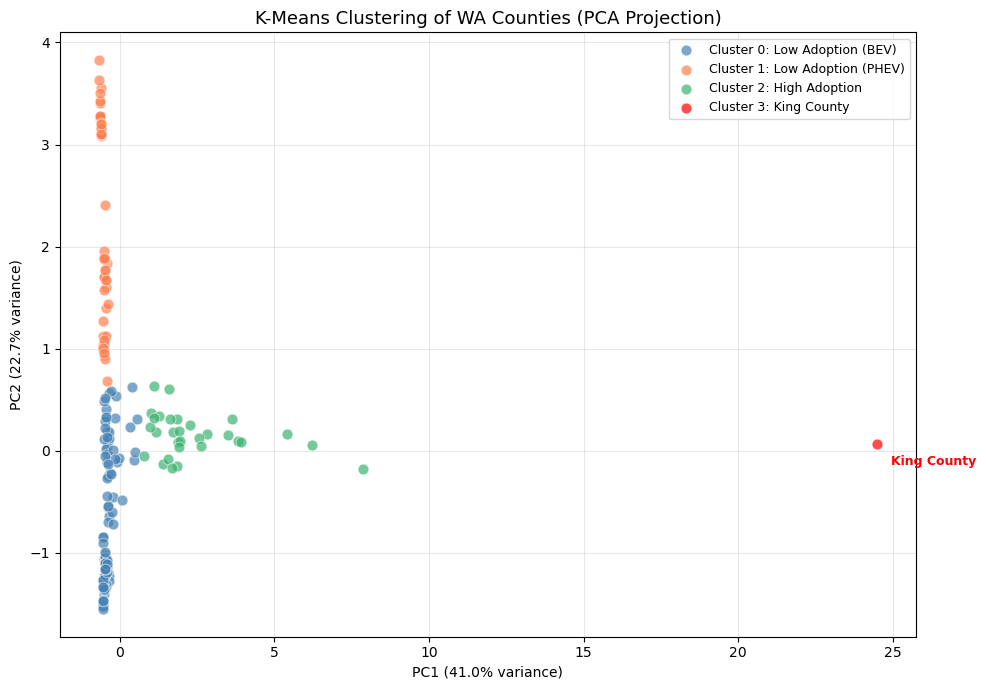

PCA scatter plot saved!


In [11]:
# PCA Scatter Plot - Colored by Cluster

cluster_labels = {
    0: 'Cluster 0: Low Adoption (BEV)',
    1: 'Cluster 1: Low Adoption (PHEV)',
    2: 'Cluster 2: High Adoption',
    3: 'Cluster 3: King County'
}

colors = ['steelblue', 'coral', 'mediumseagreen', 'red']

plt.figure(figsize=(10, 7))

for c in range(K):
    mask = county_features['Cluster'] == c
    plt.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        label=cluster_labels[c],
        color=colors[c],
        s=60, alpha=0.7, edgecolors='white', linewidth=0.5
    )
    # Annotate King County
    if c == 3:
        idx = mask[mask].index[0]
        plt.annotate(
            'King County',
            (X_pca[idx, 0], X_pca[idx, 1]),
            fontsize=9, fontweight='bold',
            xytext=(10, -15), textcoords='offset points',
            color='red'
        )

plt.title('K-Means Clustering of WA Counties (PCA Projection)', fontsize=13)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.legend(loc='upper right', fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('outputs/figures/pca_clusters.png', dpi=150)
plt.show()
print("PCA scatter plot saved!")

## Step 6: Save Results & Summary

In [12]:
# Save clustered county data

county_features.to_csv('outputs/results/county_clustered.csv', index=False)
print("Saved county_clustered.csv!")

print(f"\n{'='*50}")
print("CLUSTERING SUMMARY")
print(f"{'='*50}")
print(f"Algorithm:        K-Means")
print(f"Optimal K:        4 (Elbow + Silhouette)")
print(f"Silhouette Score: 0.4421")
print(f"Total Counties:   {len(county_features)}")
print(f"\nCluster Breakdown:")
for c in range(K):
    subset = county_features[county_features['Cluster'] == c]
    label = cluster_labels[c]
    print(f"  {label}: {len(subset)} counties")
print(f"\nKey Finding: King County (Seattle) forms its own")
print(f"cluster due to 133,815 EVs — 29x more than")
print(f"the next highest cluster average (4,535).")
print(f"\nClustering Complete! Ready for Classification.")

Saved county_clustered.csv!

CLUSTERING SUMMARY
Algorithm:        K-Means
Optimal K:        4 (Elbow + Silhouette)
Silhouette Score: 0.4421
Total Counties:   246

Cluster Breakdown:
  Cluster 0: Low Adoption (BEV): 156 counties
  Cluster 1: Low Adoption (PHEV): 59 counties
  Cluster 2: High Adoption: 30 counties
  Cluster 3: King County: 1 counties

Key Finding: King County (Seattle) forms its own
cluster due to 133,815 EVs — 29x more than
the next highest cluster average (4,535).

Clustering Complete! Ready for Classification.
